In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler
import gzip
import os

In [42]:
from google.colab import files

arquivos = files.upload()

Saving GPL6244-17930.txt to GPL6244-17930.txt
Saving GSE100930_series_matrix.txt.gz to GSE100930_series_matrix.txt (1).gz
Saving GSE100931_gene_counts_all_samples.txt.gz to GSE100931_gene_counts_all_samples.txt (2).gz


In [43]:
print("Arquivos enviados:")

for arquivo in arquivos.keys():
    print("-", arquivo)

Arquivos enviados:
- GPL6244-17930.txt
- GSE100930_series_matrix.txt (1).gz
- GSE100931_gene_counts_all_samples.txt (2).gz


In [ ]:
for arquivo in arquivos.keys():
    tamanho = os.path.getsize(arquivo) / (1024 * 1024)
    print(f"{arquivo}: {tamanho:.2f} MB")

GSE100930_RAW.tar: 53.28 MB
GSE100931_gene_counts_all_samples.txt.gz: 0.31 MB


In [7]:
arquivo = "GSE100931_gene_counts_all_samples.txt.gz"

dados_rnaseq = pd.read_csv(
    arquivo,
    sep="\t"
)

dados_rnaseq.head()

,Unnamed: 0,FM_SM_1,FM_SM_2,FM_SM_3,FM_OM_1
0,ENSG00000000003,662,748,1050,1952
1,ENSG00000000005,0,0,0,0
2,ENSG00000000419,388,714,854,1558
3,ENSG00000000457,225,390,198,360
4,ENSG00000000460,20,24,108,189


In [8]:
print("Dimensões:", dados_rnaseq.shape)
print("\nColunas:")
print(dados_rnaseq.columns.tolist())

Dimensões: (60675, 5)

Colunas:
['Unnamed: 0', 'FM_SM_1', 'FM_SM_2', 'FM_SM_3', 'FM_OM_1']


In [9]:
dados_rnaseq.head(10)

,Unnamed: 0,FM_SM_1,FM_SM_2,FM_SM_3,FM_OM_1
0,ENSG00000000003,662,748,1050,1952
1,ENSG00000000005,0,0,0,0
2,ENSG00000000419,388,714,854,1558
3,ENSG00000000457,225,390,198,360
4,ENSG00000000460,20,24,108,189
5,ENSG00000000938,0,15,14,0
6,ENSG00000000971,1599,3260,2992,10329
7,ENSG00000001036,898,752,1073,2023
8,ENSG00000001084,156,608,474,968
9,ENSG00000001167,561,534,723,788


In [10]:
dados_rnaseq.iloc[:, 0].head(20)

,Unnamed: 0
0,ENSG00000000003
1,ENSG00000000005
2,ENSG00000000419
3,ENSG00000000457
4,ENSG00000000460
5,ENSG00000000938
6,ENSG00000000971
7,ENSG00000001036
8,ENSG00000001084
9,ENSG00000001167


In [11]:
dados_rnaseq.iloc[:, 1:].describe()

,FM_SM_1,FM_SM_2,FM_SM_3,FM_OM_1
count,60675.000000,6.067500e+04,6.067500e+04,6.067500e+04
mean,244.313243,3.992895e+02,4.291938e+02,4.834314e+02
std,4301.515625,8.149280e+03,9.356889e+03,7.886559e+03
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.000000,1.200000e+01,1.650000e+01,1.900000e+01
max,914113.000000,1.774153e+06,2.114352e+06,1.589537e+06


In [12]:
dados_rnaseq = dados_rnaseq.rename(
    columns={"Unnamed: 0": "gene_id"}
)

dados_rnaseq.head()

,gene_id,FM_SM_1,FM_SM_2,FM_SM_3,FM_OM_1
0,ENSG00000000003,662,748,1050,1952
1,ENSG00000000005,0,0,0,0
2,ENSG00000000419,388,714,854,1558
3,ENSG00000000457,225,390,198,360
4,ENSG00000000460,20,24,108,189


In [13]:
print("Número de genes:", len(dados_rnaseq))
print("Genes únicos:", dados_rnaseq["gene_id"].nunique())

Número de genes: 60675
Genes únicos: 60675


In [14]:
genes = dados_rnaseq["gene_id"]

contagens = dados_rnaseq.drop(columns=["gene_id"])

contagens.head()

,FM_SM_1,FM_SM_2,FM_SM_3,FM_OM_1
0,662,748,1050,1952
1,0,0,0,0
2,388,714,854,1558
3,225,390,198,360
4,20,24,108,189


In [15]:
print("Genes:", genes.shape)
print("Contagens:", contagens.shape)

Genes: (60675,)
Contagens: (60675, 4)


In [19]:
arquivo_930 = "GSE100930_series_matrix.txt.gz"

with gzip.open(arquivo_930, "rt") as f:
    linhas = f.readlines()

print("Número de linhas:", len(linhas))

print("\nPrimeiras 20 linhas:")
for linha in linhas[:20]:
    print(linha.rstrip())

Número de linhas: 33373

Primeiras 20 linhas:
!Series_title	"SCD – Stem Cell Differentiation on board the International Space Station [microarray on total RNA]"
!Series_geo_accession	"GSE100930"
!Series_status	"Public on Jan 31 2019"
!Series_submission_date	"Jul 07 2017"
!Series_last_update_date	"Jul 25 2021"
!Series_summary	"The bone loss observed in astronauts and animal models after spaceflight is attributable to alterations in the bone tissue formation that depends from the continuous remodeling through the activities of bone-resorbing osteoclasts of hematopoietic lineage and bone-forming osteoblasts of mesenchymal origin."
!Series_summary	"This disease is frequent in aged people, but develops much more rapidly in space. Our experiment, selected by ESA (European Space Agency), aimed to determine how human bone marrow mesenchymal stem cells (hBMSCs) react and differentiate in real microgravity, on board the International Space Station, in approx. 2 weeks time."
!Series_overall_desig

In [20]:
for i, linha in enumerate(linhas):
    if "!series_matrix_table_begin" in linha:
        print("Tabela começa na linha:", i)

    if "!series_matrix_table_end" in linha:
        print("Tabela termina na linha:", i)

Tabela começa na linha: 73
Tabela termina na linha: 33372


In [21]:
dados_microarray = pd.read_csv(
    arquivo_930,
    sep="\t",
    comment="!",
    index_col=0
)

dados_microarray.head()

,GSM2696758,GSM2696759,GSM2696760,GSM2696761,GSM2696762,GSM2696763,GSM2696764,GSM2696765,GSM2696766,GSM2696767,GSM2696768,GSM2696769,GSM2696770
ID_REF,,,,,,,,,,,,,
7892501,5.54329,3.29085,3.32082,3.23217,4.32195,4.53134,3.45022,4.43073,4.67292,4.71030,3.38903,2.98848,2.90971
7892502,2.88166,2.97748,3.10922,2.95057,3.35897,2.89253,2.92752,3.33870,3.26958,3.85304,2.65967,2.44452,1.92735
7892503,2.44743,2.87725,2.56593,2.56800,2.64774,2.73942,2.84950,2.56241,3.09042,2.95327,2.48399,2.36821,1.79368
7892504,8.89748,9.16200,8.63972,9.02740,8.70411,8.79132,8.59214,8.47981,8.60595,9.19828,7.60191,7.41600,7.94263
7892505,2.93779,3.53688,2.52085,2.57712,3.21567,2.70801,3.64009,2.74515,3.28078,3.36688,2.60852,2.19485,2.40706


In [22]:
print("Dimensões:", dados_microarray.shape)
print("\nAmostras:")
print(dados_microarray.columns.tolist())

Dimensões: (33297, 13)

Amostras:
['GSM2696758', 'GSM2696759', 'GSM2696760', 'GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764', 'GSM2696765', 'GSM2696766', 'GSM2696767', 'GSM2696768', 'GSM2696769', 'GSM2696770']


In [23]:
print(dados_microarray.info())

<class 'pandas.core.frame.DataFrame'>
Index: 33297 entries, 7892501 to 8180418
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   GSM2696758  33297 non-null  float64
 1   GSM2696759  33297 non-null  float64
 2   GSM2696760  33297 non-null  float64
 3   GSM2696761  33297 non-null  float64
 4   GSM2696762  33297 non-null  float64
 5   GSM2696763  33297 non-null  float64
 6   GSM2696764  33297 non-null  float64
 7   GSM2696765  33297 non-null  float64
 8   GSM2696766  33297 non-null  float64
 9   GSM2696767  33297 non-null  float64
 10  GSM2696768  33297 non-null  float64
 11  GSM2696769  33297 non-null  float64
 12  GSM2696770  33297 non-null  float64
dtypes: float64(13)
memory usage: 3.6 MB
None


In [24]:
dados_microarray.iloc[:5, :10]

,GSM2696758,GSM2696759,GSM2696760,GSM2696761,GSM2696762,GSM2696763,GSM2696764,GSM2696765,GSM2696766,GSM2696767
ID_REF,,,,,,,,,,
7892501,5.54329,3.29085,3.32082,3.23217,4.32195,4.53134,3.45022,4.43073,4.67292,4.71030
7892502,2.88166,2.97748,3.10922,2.95057,3.35897,2.89253,2.92752,3.33870,3.26958,3.85304
7892503,2.44743,2.87725,2.56593,2.56800,2.64774,2.73942,2.84950,2.56241,3.09042,2.95327
7892504,8.89748,9.16200,8.63972,9.02740,8.70411,8.79132,8.59214,8.47981,8.60595,9.19828
7892505,2.93779,3.53688,2.52085,2.57712,3.21567,2.70801,3.64009,2.74515,3.28078,3.36688


In [25]:
for linha in linhas:
    if linha.startswith("!Sample_geo_accession"):
        print(linha.rstrip())

    if linha.startswith("!Sample_title"):
        print(linha.rstrip())

    if linha.startswith("!Sample_source_name_ch1"):
        print(linha.rstrip())

!Sample_title	"Total RNA from flight cells, Osteogenic medium, biological replicate 1_array"	"Total RNA from flight cells, Osteogenic medium, biological replicate 2_array"	"Total RNA from flight cells, Osteogenic medium, biological replicate 3_array"	"Total RNA from flight cells, Standard medium, biological replicate 1_array"	"Total RNA from flight cells, Standard medium, biological replicate 2_array"	"Total RNA from flight cells, Standard medium, biological replicate 3_array"	"Total RNA from flight cells, Standard medium, biological replicate 4_array"	"Total RNA from ground cells, Osteogenic medium, biological replicate 1_array"	"Total RNA from ground cells, Osteogenic medium, biological replicate 2_array"	"Total RNA from ground cells, Osteogenic medium, biological replicate 3_array"	"Total RNA from ground cells, Standard medium, biological replicate 1_array"	"Total RNA from ground cells, Standard medium, biological replicate 2_array"	"Total RNA from ground cells, Standard medium, bio

In [26]:
for linha in linhas:
    if linha.startswith("!Sample_characteristics_ch1"):
        print(linha.rstrip())

!Sample_characteristics_ch1	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"	"cell type: bone marrow mesenchymal stem cells"
!Sample_characteristics_ch1	"location: on board ISS"	"location: on board ISS"	"location: on board ISS"	"location: on board ISS"	"location: on board ISS"	"location: on board ISS"	"location: on board ISS"	"location: ground"	"location: ground"	"location: ground"	"location: ground"	"location: ground"	"location: ground"
!Sample_characteristics_ch1	"me

In [27]:
amostras = dados_microarray.columns.tolist()

metadados = pd.DataFrame({
    "amostra": amostras,
    "condicao": [
        "Flight", "Flight", "Flight",
        "Flight", "Flight", "Flight", "Flight",
        "Ground", "Ground", "Ground",
        "Ground", "Ground", "Ground"
    ],
    "meio": [
        "Osteogenic", "Osteogenic", "Osteogenic",
        "Standard", "Standard", "Standard", "Standard",
        "Osteogenic", "Osteogenic", "Osteogenic",
        "Standard", "Standard", "Standard"
    ]
})

metadados

,amostra,condicao,meio
0,GSM2696758,Flight,Osteogenic
1,GSM2696759,Flight,Osteogenic
2,GSM2696760,Flight,Osteogenic
3,GSM2696761,Flight,Standard
4,GSM2696762,Flight,Standard
5,GSM2696763,Flight,Standard
6,GSM2696764,Flight,Standard
7,GSM2696765,Ground,Osteogenic
8,GSM2696766,Ground,Osteogenic
9,GSM2696767,Ground,Osteogenic


In [28]:
pd.crosstab(
    metadados["condicao"],
    metadados["meio"]
)

meio,Osteogenic,Standard
condicao,,
Flight,3,4
Ground,3,3


In [29]:
metadados["grupo"] = (
    metadados["condicao"] + "_" + metadados["meio"]
)

metadados

,amostra,condicao,meio,grupo
0,GSM2696758,Flight,Osteogenic,Flight_Osteogenic
1,GSM2696759,Flight,Osteogenic,Flight_Osteogenic
2,GSM2696760,Flight,Osteogenic,Flight_Osteogenic
3,GSM2696761,Flight,Standard,Flight_Standard
4,GSM2696762,Flight,Standard,Flight_Standard
5,GSM2696763,Flight,Standard,Flight_Standard
6,GSM2696764,Flight,Standard,Flight_Standard
7,GSM2696765,Ground,Osteogenic,Ground_Osteogenic
8,GSM2696766,Ground,Osteogenic,Ground_Osteogenic
9,GSM2696767,Ground,Osteogenic,Ground_Osteogenic


In [30]:
print(dados_microarray.columns.tolist())

['GSM2696758', 'GSM2696759', 'GSM2696760', 'GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764', 'GSM2696765', 'GSM2696766', 'GSM2696767', 'GSM2696768', 'GSM2696769', 'GSM2696770']


In [31]:
print(metadados["amostra"].tolist())

['GSM2696758', 'GSM2696759', 'GSM2696760', 'GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764', 'GSM2696765', 'GSM2696766', 'GSM2696767', 'GSM2696768', 'GSM2696769', 'GSM2696770']


In [32]:
flight_osteogenic = metadados[
    metadados["grupo"] == "Flight_Osteogenic"
]["amostra"].tolist()

flight_standard = metadados[
    metadados["grupo"] == "Flight_Standard"
]["amostra"].tolist()

ground_osteogenic = metadados[
    metadados["grupo"] == "Ground_Osteogenic"
]["amostra"].tolist()

ground_standard = metadados[
    metadados["grupo"] == "Ground_Standard"
]["amostra"].tolist()

In [33]:
print("Flight + Osteogenic:", flight_osteogenic)
print("Flight + Standard:", flight_standard)
print("Ground + Osteogenic:", ground_osteogenic)
print("Ground + Standard:", ground_standard)

Flight + Osteogenic: ['GSM2696758', 'GSM2696759', 'GSM2696760']
Flight + Standard: ['GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764']
Ground + Osteogenic: ['GSM2696765', 'GSM2696766', 'GSM2696767']
Ground + Standard: ['GSM2696768', 'GSM2696769', 'GSM2696770']


In [34]:
print("Ordem das colunas:")
print(dados_microarray.columns.tolist())

print("\nOrdem dos metadados:")
print(metadados["amostra"].tolist())

print("\nAs ordens são iguais?")
print(dados_microarray.columns.tolist() == metadados["amostra"].tolist())

Ordem das colunas:
['GSM2696758', 'GSM2696759', 'GSM2696760', 'GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764', 'GSM2696765', 'GSM2696766', 'GSM2696767', 'GSM2696768', 'GSM2696769', 'GSM2696770']

Ordem dos metadados:
['GSM2696758', 'GSM2696759', 'GSM2696760', 'GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764', 'GSM2696765', 'GSM2696766', 'GSM2696767', 'GSM2696768', 'GSM2696769', 'GSM2696770']

As ordens são iguais?
True


In [35]:
estatisticas = dados_microarray.describe().T[
    ["min", "25%", "50%", "75%", "max", "mean", "std"]
]

estatisticas

,min,25%,50%,75%,max,mean,std
GSM2696758,1.62171,3.49473,4.85338,6.70191,14.1080,5.305892,2.226560
GSM2696759,1.78198,3.55258,4.89845,6.69001,14.1795,5.331701,2.211163
GSM2696760,1.78746,3.54221,4.92261,6.65357,13.8280,5.305363,2.194617
GSM2696761,1.61711,3.52676,4.88874,6.65985,13.8923,5.304353,2.218406
GSM2696762,1.87571,3.51699,4.87262,6.67509,14.1202,5.301871,2.205924
GSM2696763,1.80881,3.52482,4.87901,6.67592,13.8946,5.303260,2.209048
GSM2696764,1.84803,3.45194,4.78092,6.71592,14.2240,5.280555,2.241233
GSM2696765,1.72075,3.46927,4.80985,6.70753,13.9603,5.298566,2.251798
GSM2696766,2.24191,3.61091,4.69363,6.78488,13.8773,5.418146,2.292547
GSM2696767,2.07867,3.63981,4.66462,6.79317,13.9850,5.427557,2.267340


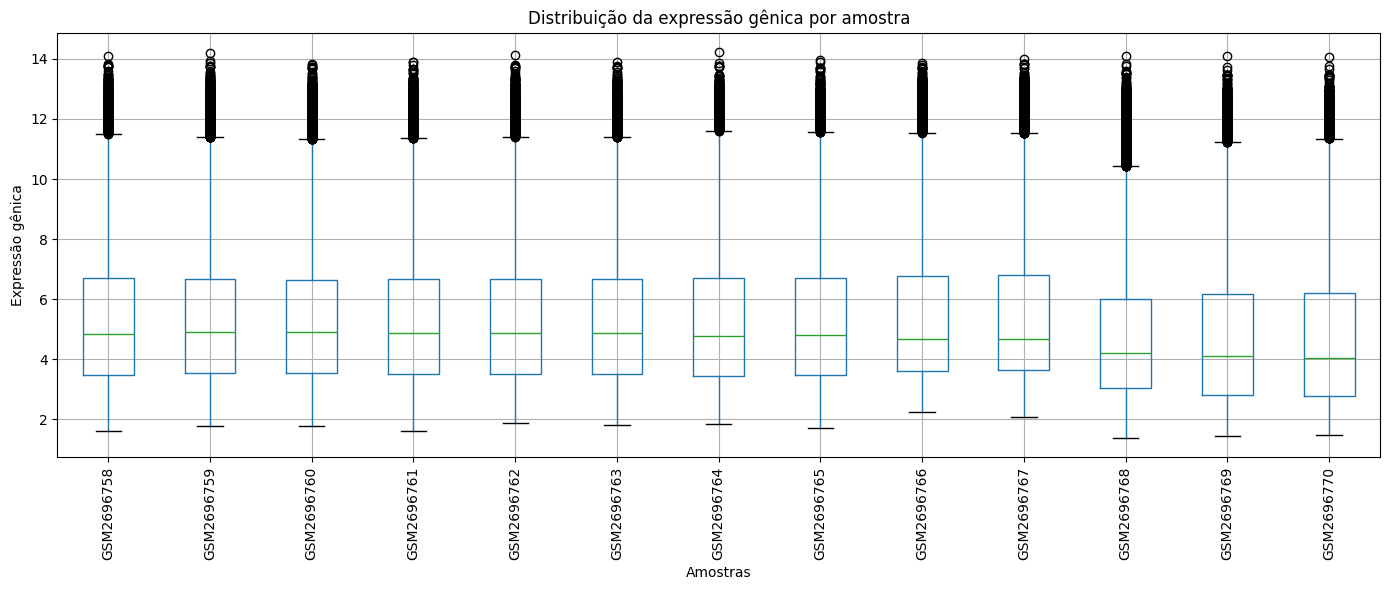

In [37]:
plt.figure(figsize=(14, 6))

dados_microarray.boxplot()

plt.title("Distribuição da expressão gênica por amostra")
plt.xlabel("Amostras")
plt.ylabel("Expressão gênica")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [39]:
X = dados_microarray.T

# Padronizar os dados
X_padronizado = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_padronizado)

# Criar dataframe com os resultados
pca_df = pd.DataFrame(
    componentes,
    columns=["PC1", "PC2"],
    index=dados_microarray.columns
)

# Adicionar os metadados
pca_df["condicao"] = metadados["condicao"].values
pca_df["meio"] = metadados["meio"].values
pca_df["grupo"] = metadados["grupo"].values

pca_df

,PC1,PC2,condicao,meio,grupo
GSM2696758,44.717488,-58.640679,Flight,Osteogenic,Flight_Osteogenic
GSM2696759,60.588284,-59.820440,Flight,Osteogenic,Flight_Osteogenic
GSM2696760,54.998416,-70.611078,Flight,Osteogenic,Flight_Osteogenic
GSM2696761,54.128163,-72.618494,Flight,Standard,Flight_Standard
GSM2696762,54.108911,-70.069412,Flight,Standard,Flight_Standard
GSM2696763,59.340660,-72.464340,Flight,Standard,Flight_Standard
GSM2696764,26.467412,-52.781239,Flight,Standard,Flight_Standard
GSM2696765,61.175411,33.480827,Ground,Osteogenic,Ground_Osteogenic
GSM2696766,123.903713,150.729756,Ground,Osteogenic,Ground_Osteogenic
GSM2696767,132.624313,177.619457,Ground,Osteogenic,Ground_Osteogenic


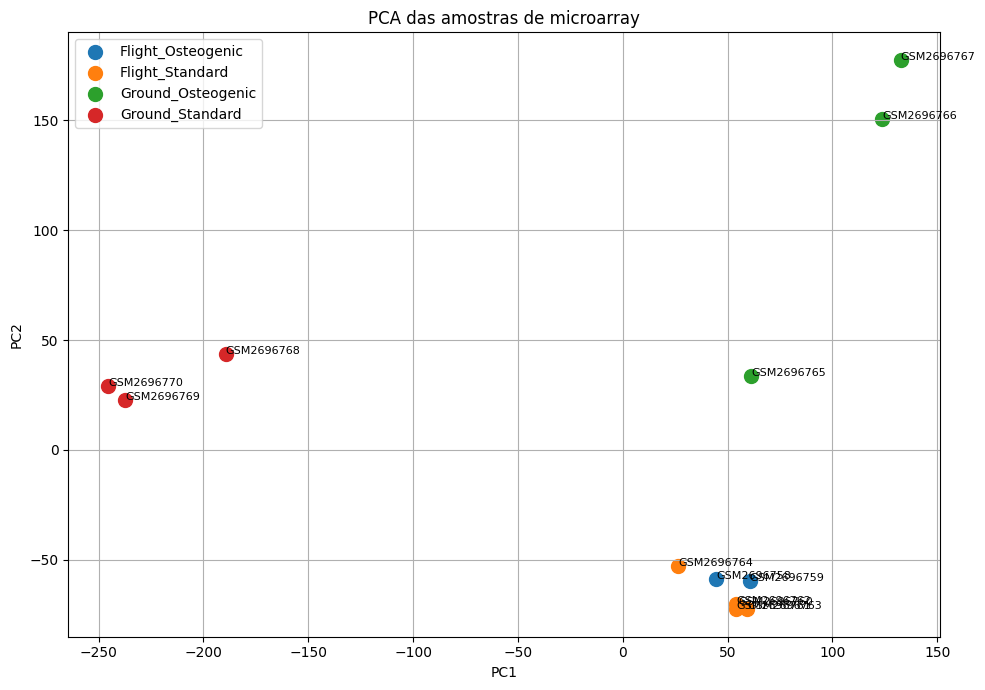

In [40]:
plt.figure(figsize=(10, 7))

for grupo in pca_df["grupo"].unique():

    dados_grupo = pca_df[pca_df["grupo"] == grupo]

    plt.scatter(
        dados_grupo["PC1"],
        dados_grupo["PC2"],
        s=100,
        label=grupo
    )

    # Nome da amostra ao lado do ponto
    for nome, x, y in zip(
        dados_grupo.index,
        dados_grupo["PC1"],
        dados_grupo["PC2"]
    ):
        plt.annotate(nome, (x, y), fontsize=8)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA das amostras de microarray")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [44]:
arquivo_gpl = "GPL6244-17930.txt"

with open(arquivo_gpl, "r", encoding="utf-8", errors="ignore") as f:
    for i in range(15):
        print(f.readline().rstrip())

#ID = transcript_cluster_id
#GB_LIST = GenBank and RefSeq Accessions from mrna_assignment column
#SPOT_ID = genomic location of the transcript cluster in the version of the genome assembly used at annotation time. Coordinates are standard 1-based (length=stop-start+1).
#seqname = chromosome number
#RANGE_GB = NCBI RefSeq for chromosome of current build
#RANGE_STRAND = strand  (+|-)
#RANGE_START = start  (integer). Coordinates are standard 1-based (length=stop-start+1).
#RANGE_STOP = stop  (integer). Coordinates are standard 1-based (length=stop-start+1).
#total_probes = Total number of probes contained by this transcript cluster.
#gene_assignment = Gene information for each assigned mRNA for mRNAs that corresponds to known genes (multipart).
#mrna_assignment = Description of the public mRNAs that should be detected by the sets within this transcript cluster based on sequence alignment (multipart).
#category = Array design category of the transcript cluster
ID	GB_LIST	SPOT_ID	seqname	RA

In [45]:
arquivo_gpl = "GPL6244-17930.txt"

anotacao_gpl = pd.read_csv(
    arquivo_gpl,
    sep="\t",
    comment="#",
    dtype=str
)

print("Dimensão:", anotacao_gpl.shape)
print("\nColunas:")
print(anotacao_gpl.columns.tolist())

anotacao_gpl.head()

Dimensão: (33297, 12)

Colunas:
['ID', 'GB_LIST', 'SPOT_ID', 'seqname', 'RANGE_GB', 'RANGE_STRAND', 'RANGE_START', 'RANGE_STOP', 'total_probes', 'gene_assignment', 'mrna_assignment', 'category']


,ID,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category
0,7896736,NaN,chr1:53049-54936,chr1,NC_000001.10,+,53049,54936,7,---,NONHSAT060105 // NONCODE // Non-coding transcr...,main
1,7896738,NaN,chr1:63015-63887,chr1,NC_000001.10,+,63015,63887,31,ENST00000328113 // OR4G2P // olfactory recepto...,ENST00000328113 // ENSEMBL // havana:known chr...,main
2,7896740,"NM_001004195,NM_001005240,NM_001005484,BC13684...",chr1:69091-70008,chr1,NC_000001.10,+,69091,70008,24,"NM_001004195 // OR4F4 // olfactory receptor, f...",NM_001004195 // RefSeq // Homo sapiens olfacto...,main
3,7896742,"NR_024437,XM_006711854,XM_006726377,XR_430662,...",chr1:334129-334296,chr1,NC_000001.10,+,334129,334296,6,NR_024437 // LOC728323 // uncharacterized LOC7...,NR_024437 // RefSeq // Homo sapiens uncharacte...,main
4,7896744,"NM_001005221,NM_001005224,NM_001005277,NM_0010...",chr1:367659-368597,chr1,NC_000001.10,+,367659,368597,36,"NM_001005221 // OR4F29 // olfactory receptor, ...",NM_001005221 // RefSeq // Homo sapiens olfacto...,main


In [46]:
# IDs dos probes presentes na matriz de expressão
probes_microarray = dados_microarray.index.astype(str)

# IDs disponíveis na anotação GPL6244
probes_gpl = anotacao_gpl["ID"].astype(str)

# Verificar quais probes foram encontrados
probes_encontrados = probes_microarray.isin(probes_gpl)

print("Total de probes na matriz:", len(probes_microarray))
print("Probes encontrados no GPL6244:", probes_encontrados.sum())
print("Probes não encontrados:", (~probes_encontrados).sum())

Total de probes na matriz: 33297
Probes encontrados no GPL6244: 33297
Probes não encontrados: 0


In [48]:
# Fazer uma cópia da anotação
anotacao = anotacao_gpl[["ID", "gene_assignment"]].copy()

# Garantir que o ID tenha o mesmo tipo da matriz
anotacao["ID"] = anotacao["ID"].astype(str)

# Extrair o símbolo do gene

def extrair_gene(valor):
    if pd.isna(valor) or valor == "---":
        return None

    # Pode haver várias anotações separadas por " /// "
    primeira_anotacao = str(valor).split(" /// ")[0]

    partes = primeira_anotacao.split(" // ")

    if len(partes) >= 2:
        return partes[1].strip()

    return None

anotacao["gene"] = anotacao["gene_assignment"].apply(extrair_gene)

anotacao.head()

,ID,gene_assignment,gene
0,7896736,---,None
1,7896738,ENST00000328113 // OR4G2P // olfactory recepto...,OR4G2P
2,7896740,"NM_001004195 // OR4F4 // olfactory receptor, f...",OR4F4
3,7896742,NR_024437 // LOC728323 // uncharacterized LOC7...,LOC728323
4,7896744,"NM_001005221 // OR4F29 // olfactory receptor, ...",OR4F29


In [49]:
# Preparar a matriz de expressão
expressao = dados_microarray.copy()

# Transformar o ID do probe em string
expressao.index = expressao.index.astype(str)

# Colocar o ID do probe em uma coluna
expressao = expressao.reset_index()
expressao = expressao.rename(columns={"ID_REF": "ID"})

# Juntar com a anotação GPL6244
expressao_anotada = expressao.merge(
    anotacao[["ID", "gene"]],
    on="ID",
    how="left"
)

print("Dimensão:", expressao_anotada.shape)

expressao_anotada.head()

Dimensão: (33297, 15)


,ID,GSM2696758,GSM2696759,GSM2696760,GSM2696761,GSM2696762,GSM2696763,GSM2696764,GSM2696765,GSM2696766,GSM2696767,GSM2696768,GSM2696769,GSM2696770,gene
0,7892501,5.54329,3.29085,3.32082,3.23217,4.32195,4.53134,3.45022,4.43073,4.67292,4.71030,3.38903,2.98848,2.90971,None
1,7892502,2.88166,2.97748,3.10922,2.95057,3.35897,2.89253,2.92752,3.33870,3.26958,3.85304,2.65967,2.44452,1.92735,None
2,7892503,2.44743,2.87725,2.56593,2.56800,2.64774,2.73942,2.84950,2.56241,3.09042,2.95327,2.48399,2.36821,1.79368,None
3,7892504,8.89748,9.16200,8.63972,9.02740,8.70411,8.79132,8.59214,8.47981,8.60595,9.19828,7.60191,7.41600,7.94263,None
4,7892505,2.93779,3.53688,2.52085,2.57712,3.21567,2.70801,3.64009,2.74515,3.28078,3.36688,2.60852,2.19485,2.40706,None


In [50]:
genes_interesse = [
    "RUNX2",
    "ALPL",
    "BGLAP",
    "COL1A1",
    "SP7",
    "BMP2",
    "SPP1"
]

for gene in genes_interesse:
    resultado = expressao_anotada[
        expressao_anotada["gene"] == gene
    ]

    print(f"{gene}: {len(resultado)} probe(s)")

RUNX2: 1 probe(s)
ALPL: 1 probe(s)
BGLAP: 1 probe(s)
COL1A1: 1 probe(s)
SP7: 1 probe(s)
BMP2: 1 probe(s)
SPP1: 1 probe(s)


In [51]:
genes_interesse = [
    "RUNX2",
    "ALPL",
    "BGLAP",
    "COL1A1",
    "SP7",
    "BMP2",
    "SPP1"
]

# Selecionar somente os genes de interesse
genes_resultado = expressao_anotada[
    expressao_anotada["gene"].isin(genes_interesse)
].copy()

# Colocar o gene como índice
genes_resultado = genes_resultado.set_index("gene")

# Mostrar somente as expressões
genes_resultado

,ID,GSM2696758,GSM2696759,GSM2696760,GSM2696761,GSM2696762,GSM2696763,GSM2696764,GSM2696765,GSM2696766,GSM2696767,GSM2696768,GSM2696769,GSM2696770
gene,,,,,,,,,,,,,,
ALPL,7898693,6.25025,6.36800,6.33868,4.95856,5.03299,4.65614,5.07729,7.34977,8.00838,7.60865,3.94046,3.56100,4.26777
BGLAP,7906140,9.87020,9.20825,9.91902,5.91683,5.83534,6.00349,5.93122,7.84898,7.80538,7.15824,6.09587,5.81120,6.02305
SP7,7963664,5.57193,5.26740,5.54891,5.68692,5.66457,5.62821,5.51742,5.52462,4.63385,4.63668,4.72745,4.81238,4.55025
COL1A1,8016646,9.67680,9.22875,9.56680,9.32517,10.04390,9.57894,9.93187,7.42848,7.50791,7.40248,7.04817,8.75017,9.38921
BMP2,8060850,4.68457,4.59787,4.90417,4.88367,4.69355,4.88367,4.41941,4.88367,4.98999,4.95416,4.32845,4.00008,3.42931
SPP1,8096301,9.60967,9.03188,9.47575,6.00020,5.89540,6.03527,6.69418,9.17585,9.47219,9.47004,4.96464,5.77877,4.83445
RUNX2,8120043,8.27948,8.08398,8.17400,7.79025,7.82026,7.79025,8.07535,6.20832,5.53251,5.53251,6.84281,6.84377,6.36496


In [52]:
genes_interesse = [
    "RUNX2",
    "ALPL",
    "BGLAP",
    "COL1A1",
    "SP7",
    "BMP2",
    "SPP1"
]

# Criar tabela com as médias por grupo
medias = {}

for gene in genes_interesse:
    valores = genes_resultado.loc[gene]

    medias[gene] = {
        "Flight_Osteogenic": valores[flight_osteogenic].mean(),
        "Ground_Osteogenic": valores[ground_osteogenic].mean(),
        "Flight_Standard": valores[flight_standard].mean(),
        "Ground_Standard": valores[ground_standard].mean()
    }

medias_df = pd.DataFrame(medias).T

medias_df

,Flight_Osteogenic,Ground_Osteogenic,Flight_Standard,Ground_Standard
RUNX2,8.179153,5.757780,7.869028,6.683847
ALPL,6.318977,7.655600,4.931245,3.923077
BGLAP,9.665823,7.604200,5.921720,5.976707
COL1A1,9.490783,7.446290,9.719970,8.395850
SP7,5.462747,4.931717,5.624280,4.696693
BMP2,4.728870,4.942607,4.720075,3.919280
SPP1,9.372433,9.372693,6.156263,5.192620


In [53]:
log2fc = pd.DataFrame(index=genes_interesse)

log2fc["Osteogenic"] = np.log2(
    medias_df["Flight_Osteogenic"] /
    medias_df["Ground_Osteogenic"]
)

log2fc["Standard"] = np.log2(
    medias_df["Flight_Standard"] /
    medias_df["Ground_Standard"]
)

log2fc

,Osteogenic,Standard
RUNX2,0.506439,0.235507
ALPL,-0.276825,0.329966
BGLAP,0.346096,-0.013334
COL1A1,0.350005,0.211275
SP7,0.147537,0.260023
BMP2,-0.063777,0.268221
SPP1,-0.000040,0.245592


In [55]:
resultados = []

for gene in genes_interesse:

    # Valores individuais
    flight_osteo = genes_resultado.loc[gene, flight_osteogenic].astype(float)
    ground_osteo = genes_resultado.loc[gene, ground_osteogenic].astype(float)

    flight_std = genes_resultado.loc[gene, flight_standard].astype(float)
    ground_std = genes_resultado.loc[gene, ground_standard].astype(float)

    # Welch t-test
    t_osteo, p_osteo = ttest_ind(
        flight_osteo,
        ground_osteo,
        equal_var=False
    )

    t_std, p_std = ttest_ind(
        flight_std,
        ground_std,
        equal_var=False
    )

    resultados.append({
        "gene": gene,
        "p_Osteogenic": p_osteo,
        "p_Standard": p_std
    })

resultados_df = pd.DataFrame(resultados)

resultados_df

,gene,p_Osteogenic,p_Standard
0,RUNX2,0.005974,0.008392
1,ALPL,0.017278,0.022836
2,BGLAP,0.002995,0.597391
3,COL1A1,0.002923,0.193463
4,SP7,0.208418,0.001827
5,BMP2,0.132503,0.075664
6,SPP1,0.999043,0.058627


In [57]:
# FDR para Osteogenic
resultados_df["FDR_Osteogenic"] = multipletests(
    resultados_df["p_Osteogenic"],
    method="fdr_bh"
)[1]

# FDR para Standard
resultados_df["FDR_Standard"] = multipletests(
    resultados_df["p_Standard"],
    method="fdr_bh"
)[1]

resultados_df

,gene,p_Osteogenic,p_Standard,FDR_Osteogenic,FDR_Standard
0,RUNX2,0.005974,0.008392,0.013940,0.029374
1,ALPL,0.017278,0.022836,0.030236,0.053283
2,BGLAP,0.002995,0.597391,0.010482,0.597391
3,COL1A1,0.002923,0.193463,0.010482,0.225707
4,SP7,0.208418,0.001827,0.243154,0.012790
5,BMP2,0.132503,0.075664,0.185504,0.105930
6,SPP1,0.999043,0.058627,0.999043,0.102597


In [58]:
resultados_completo = resultados_df.copy()

resultados_completo["log2FC_Osteogenic"] = log2fc["Osteogenic"].values
resultados_completo["log2FC_Standard"] = log2fc["Standard"].values

resultados_completo = resultados_completo[
    [
        "gene",
        "log2FC_Osteogenic",
        "p_Osteogenic",
        "FDR_Osteogenic",
        "log2FC_Standard",
        "p_Standard",
        "FDR_Standard"
    ]
]

resultados_completo

,gene,log2FC_Osteogenic,p_Osteogenic,FDR_Osteogenic,log2FC_Standard,p_Standard,FDR_Standard
0,RUNX2,0.506439,0.005974,0.013940,0.235507,0.008392,0.029374
1,ALPL,-0.276825,0.017278,0.030236,0.329966,0.022836,0.053283
2,BGLAP,0.346096,0.002995,0.010482,-0.013334,0.597391,0.597391
3,COL1A1,0.350005,0.002923,0.010482,0.211275,0.193463,0.225707
4,SP7,0.147537,0.208418,0.243154,0.260023,0.001827,0.012790
5,BMP2,-0.063777,0.132503,0.185504,0.268221,0.075664,0.105930
6,SPP1,-0.000040,0.999043,0.999043,0.245592,0.058627,0.102597


In [59]:
log2fc_correto = pd.DataFrame(index=genes_interesse)

log2fc_correto["Osteogenic"] = (
    medias_df["Flight_Osteogenic"]
    - medias_df["Ground_Osteogenic"]
)

log2fc_correto["Standard"] = (
    medias_df["Flight_Standard"]
    - medias_df["Ground_Standard"]
)

log2fc_correto

,Osteogenic,Standard
RUNX2,2.421373,1.185181
ALPL,-1.336623,1.008168
BGLAP,2.061623,-0.054987
COL1A1,2.044493,1.324120
SP7,0.531030,0.927587
BMP2,-0.213737,0.800795
SPP1,-0.000260,0.963642


In [60]:
resultado_final = resultados_df.copy()

resultado_final["log2FC_Osteogenic"] = (
    log2fc_correto["Osteogenic"].values
)

resultado_final["log2FC_Standard"] = (
    log2fc_correto["Standard"].values
)

resultado_final = resultado_final[
    [
        "gene",
        "log2FC_Osteogenic",
        "p_Osteogenic",
        "FDR_Osteogenic",
        "log2FC_Standard",
        "p_Standard",
        "FDR_Standard"
    ]
]

resultado_final

,gene,log2FC_Osteogenic,p_Osteogenic,FDR_Osteogenic,log2FC_Standard,p_Standard,FDR_Standard
0,RUNX2,2.421373,0.005974,0.013940,1.185181,0.008392,0.029374
1,ALPL,-1.336623,0.017278,0.030236,1.008168,0.022836,0.053283
2,BGLAP,2.061623,0.002995,0.010482,-0.054987,0.597391,0.597391
3,COL1A1,2.044493,0.002923,0.010482,1.324120,0.193463,0.225707
4,SP7,0.531030,0.208418,0.243154,0.927587,0.001827,0.012790
5,BMP2,-0.213737,0.132503,0.185504,0.800795,0.075664,0.105930
6,SPP1,-0.000260,0.999043,0.999043,0.963642,0.058627,0.102597
